X_train: (240, 64, 64), y_train: (240,)
X_val:   (80, 64, 64), y_val:   (80,)
X_test:  (80, 64, 64), y_test:  (80,)
X_test_corrupted:  (80, 64, 64), y_test:  (80,)
Single Tree | Clean Acc:0.6500 | Clean Conf:0.9750 | Masked Acc:0.3500 | Masked Conf:1.0000
Bagging (Depth=None, Min_leaf=2, B=200) | Clean Acc:0.8500 | Clean Conf::0.4117 | Masked Acc:0.6375 | Masked Conf:0.2697
Boosting (Depth=3, T=100) | 0.4500 | 0.1010 | 0.3625 | 0.1013

CASE STUDY DISAGREEMENT (Test Sample Index 1):
True Label:39
Bagging Prediction:12 (Correct:False)
Boosting Prediction:14 (Correct:False)


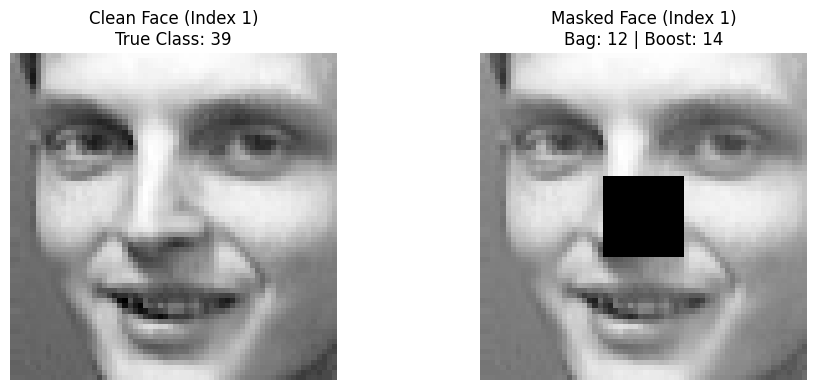

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import fetch_olivetti_faces
import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q2_d.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

faces = fetch_olivetti_faces(shuffle=False)
X = faces.images
y = faces.target

height = X.shape[1]
width = X.shape[2]

split_data = np.load("olivetti_split_indices.npz")

train_idx = split_data["train"]
val_idx = split_data["val"]
test_idx = split_data["test"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_corrupted = X_test.copy()
X_test_corrupted[:, 24:40, 24:40] = 0.0

logger.info(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
logger.info(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
logger.info(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
logger.info(f"X_test_corrupted:  {X_test_corrupted.shape}, y_test:  {y_test.shape}")




X_train = X_train.reshape(-1, height * width)
X_val = X_val.reshape(-1, height * width)
X_test = X_test.reshape(-1, height * width)
X_test_corrupted = X_test_corrupted.reshape(-1, height * width)

n_train = len(X_train)

def fit_samme_adaboost(X_flat, y, n_estimators, max_depth):

    N = len(y)
    classes = np.unique(y)
    K = len(classes)
    top_k = 10

    w = np.ones(N, dtype=np.float64) / N

    estimators = []
    estimator_weights = []

    history = {
        "eps_ts": [],
        "alphas": [],
        "max_sample_weights": [],
        "top10_weights": [],
        "sample_weights_over_time": []
    }
    
    for t in range(n_estimators):
        clf = DecisionTreeClassifier(max_depth=max_depth, random_state=seed + t)
        clf.fit(X_flat, y, sample_weight=w)

        preds = clf.predict(X_flat)
        incorrect = (preds != y)

        eps_t = np.sum(w * incorrect) / np.sum(w)

        random_guess_error = 1.0 - (1.0 / K)
        if eps_t >= random_guess_error:
            if t == 0:
                alpha_t = 1e-10
                estimators.append(clf)
                estimator_weights.append(alpha_t)
            break

        if eps_t == 0:
            alpha_t = 100.0
        else:
            alpha_t = np.log((1.0 - eps_t) / eps_t) + np.log(K - 1)

        w_updated = w * np.exp(alpha_t * incorrect)

        w_next = w_updated / np.sum(w_updated)

        estimators.append(clf)
        estimator_weights.append(alpha_t)

        history["eps_ts"].append(eps_t)
        history["alphas"].append(alpha_t)
        history["max_sample_weights"].append(np.max(w_next))
        
        history["top10_weights"].append(np.sum(np.sort(w_next)[-top_k:]))
        history["sample_weights_over_time"].append(w_next.copy())

        w = w_next

    return estimators, estimator_weights, classes, history

def evaluate_single_tree(tree, X_flat, y_true):
    preds = tree.predict(X_flat)
    acc = np.mean(preds == y_true)
    probas = tree.predict_proba(X_flat)
    max_probas = np.max(probas, axis=1)
    mean_confidence = np.mean(max_probas)
    return preds, acc, mean_confidence

def evaluate_bagging(trees, X_flat, y_true):
    all_preds = np.array([clf.predict(X_flat) for clf in trees])
    N_samples = X_flat.shape[0]
    
    final_preds = np.zeros(N_samples, dtype=int)
    winning_vote_fractions = np.zeros(N_samples)

    for i in range(N_samples):
        column_votes = all_preds[:, i]
        classes, counts = np.unique(column_votes, return_counts=True)
        max_idx = np.argmax(counts)
        final_preds[i] = classes[max_idx]
        winning_vote_fractions[i] = counts[max_idx] / len(trees)

    acc = np.mean(final_preds == y_true)
    mean_winning_fraction = np.mean(winning_vote_fractions)
    return final_preds, acc, mean_winning_fraction, all_preds

def evaluate_boosting(estimators, estimator_weights, classes, X_flat, y_true):
    N_samples = X_flat.shape[0]
    K_classes = len(classes)
    scores = np.zeros((N_samples, K_classes))

    for clf, alpha in zip(estimators, estimator_weights):
        preds = clf.predict(X_flat)
        for k_idx, c in enumerate(classes):
            scores[:, k_idx] += alpha * (preds == c)

    total_alpha = np.sum(estimator_weights)
    normalized_scores = scores / total_alpha if total_alpha > 0 else scores / K_classes

    best_class_indices = np.argmax(normalized_scores, axis=1)
    final_preds = classes[best_class_indices]

    acc = np.mean(final_preds == y_true)
    mean_winning_score = np.mean(np.max(normalized_scores, axis=1))
    return final_preds, acc, mean_winning_score, normalized_scores

seed = 260007
rng = np.random.default_rng(seed=seed)

#Single Tree Baseline (max_depth=None, min_samples_leaf=2) taken from Q1_a
single_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=seed)
single_tree.fit(X_train, y_train)

#Final Bagged Model (B = 200) taken from Q1_b. Q2_c gave 100
B_selected = 200
bagging_trees = []
for b in range(B_selected):
    boot_idx = rng.choice(n_train, size=n_train, replace=True)
    clf = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=seed + b)
    clf.fit(X_train[boot_idx], y_train[boot_idx])
    bagging_trees.append(clf)

#Final Boosting Model (Depth = 3, T = 100), taken from Q2_b
boosting_depth = 3
T_selected = 100
boosting_estimators, boosting_weights, classes, boost_history = fit_samme_adaboost(
    X_train, y_train, n_estimators=T_selected, max_depth=boosting_depth
)

_, tree_clean_acc, tree_clean_conf = evaluate_single_tree(single_tree, X_test, y_test)
_, tree_corrupt_acc, tree_corrupt_conf = evaluate_single_tree(single_tree, X_test_corrupted, y_test)

bag_clean_preds, bag_clean_acc, bag_clean_conf, bag_clean_votes = evaluate_bagging(bagging_trees, X_test, y_test)
bag_corrupt_preds, bag_corrupt_acc, bag_corrupt_conf, bag_corrupt_votes = evaluate_bagging(bagging_trees, X_test_corrupted, y_test)

boost_clean_preds, boost_clean_acc, boost_clean_conf, boost_clean_scores = evaluate_boosting(boosting_estimators, boosting_weights, classes, X_test, y_test)
boost_corrupt_preds, boost_corrupt_acc, boost_corrupt_conf, boost_corrupt_scores = evaluate_boosting(boosting_estimators, boosting_weights, classes, X_test_corrupted, y_test)

logger.info("=" * 85)
logger.info(f"{'Single Tree'} | Clean Acc:{tree_clean_acc:.4f} | Clean Conf:{tree_clean_conf:.4f} | Masked Acc:{tree_corrupt_acc:.4f} | Masked Conf:{tree_corrupt_conf:.4f}")
logger.info(f"{'Bagging (Depth=None, Min_leaf=2, B=200)'} | Clean Acc:{bag_clean_acc:.4f} | Clean Conf::{bag_clean_conf:.4f} | Masked Acc:{bag_corrupt_acc:.4f} | Masked Conf:{bag_corrupt_conf:.4f}")
logger.info(f"{'Boosting (Depth=3, T=100)'} | {boost_clean_acc:.4f} | {boost_clean_conf:.4f} | {boost_corrupt_acc:.4f} | {boost_corrupt_conf:.4f}")
logger.info("=" * 85 + "\n")

disagree_indices = []
for i in range(len(y_test)):
    if bag_corrupt_preds[i] != boost_corrupt_preds[i]:
        disagree_indices.append(i)

selected_case_idx = disagree_indices[0]

true_class = y_test[selected_case_idx]
bag_pred_cls = bag_corrupt_preds[selected_case_idx]
boost_pred_cls = boost_corrupt_preds[selected_case_idx]

logger.info("=" * 70)
logger.info(f"CASE STUDY DISAGREEMENT (Test Sample Index {selected_case_idx}):")
logger.info(f"True Label:{true_class}")
logger.info(f"Bagging Prediction:{bag_pred_cls} (Correct:{bag_pred_cls == true_class})")
logger.info(f"Boosting Prediction:{boost_pred_cls} (Correct:{boost_pred_cls == true_class})")
logger.info("=" * 70)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(X_test[selected_case_idx].reshape(height, width), cmap="gray")
axes[0].set_title(f"Clean Face (Index {selected_case_idx})\nTrue Class: {true_class}")
axes[0].axis("off")

axes[1].imshow(X_test_corrupted[selected_case_idx].reshape(height, width), cmap="gray")
axes[1].set_title(f"Masked Face (Index {selected_case_idx})\nBag: {bag_pred_cls} | Boost: {boost_pred_cls}")
axes[1].axis("off")

plt.tight_layout()

plt.savefig("q2_d_bag_boost_on_mask.png", dpi=300, bbox_inches="tight")

plt.show()

CASE STUDY DISAGREEMENT (Test Sample Index 1):
True Class Label:     39
Bagging Prediction:   Class 12 (Correct: False)
Boosting Prediction:  Class 14 (Correct: False)

--- BAGGING TREE DISAGREEMENT BREAKDOWN ---
Class 12: 42  votes (21.0%)
Class 35: 28  votes (14.0%)
Class 20: 16  votes (8.0%)

--- BOOSTING WEIGHTED VOTE (CONFIDENCE) BREAKDOWN ---
Class 14: Normalized Score = 0.1019
Class 3 : Normalized Score = 0.1017
Class 12: Normalized Score = 0.0910
--- FINAL BOOSTING SAMPLE WEIGHT DISTRIBUTION IN TRAINING DATA ---
Total Weight on True Class 39 Training Images:       0.006610
Total Weight on Predicted Class 14 Training Images:  0.043040



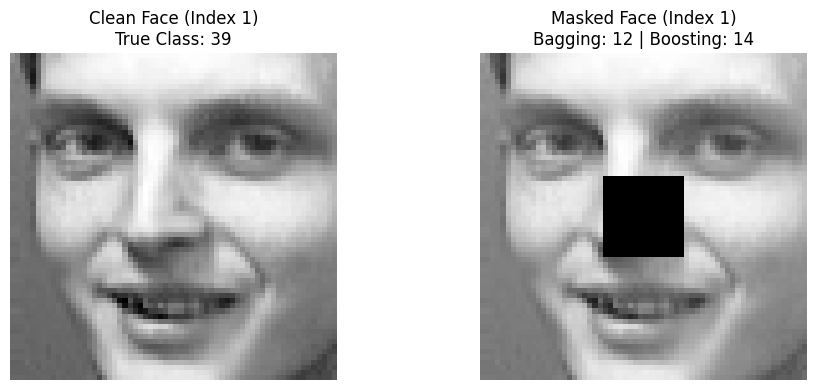

In [2]:
true_class = y_test[selected_case_idx]
bag_pred_cls = bag_corrupt_preds[selected_case_idx]
boost_pred_cls = boost_corrupt_preds[selected_case_idx]

logger.info("=" * 70)
logger.info(f"CASE STUDY DISAGREEMENT (Test Sample Index {selected_case_idx}):")
logger.info(f"True Class Label:     {true_class}")
logger.info(f"Bagging Prediction:   Class {bag_pred_cls} (Correct: {bag_pred_cls == true_class})")
logger.info(f"Boosting Prediction:  Class {boost_pred_cls} (Correct: {boost_pred_cls == true_class})")
logger.info("=" * 70)

sample_bag_votes = bag_corrupt_votes[:, selected_case_idx]
bag_classes, bag_counts = np.unique(sample_bag_votes, return_counts=True)
sorted_bag_idx = np.argsort(bag_counts)[::-1]

logger.info("\n--- BAGGING TREE DISAGREEMENT BREAKDOWN ---")
for idx in sorted_bag_idx[:3]:
    cls = bag_classes[idx]
    cnt = bag_counts[idx]
    logger.info(f"Class {cls:<2}: {cnt:<3} votes ({cnt / B_selected * 100:.1f}%)")

sample_boost_scores = boost_corrupt_scores[selected_case_idx]
sorted_boost_idx = np.argsort(sample_boost_scores)[::-1]

logger.info("\n--- BOOSTING WEIGHTED VOTE (CONFIDENCE) BREAKDOWN ---")
for idx in sorted_boost_idx[:3]:
    cls = classes[idx]
    score = sample_boost_scores[idx]
    logger.info(f"Class {cls:<2}: Normalized Score = {score:.4f}")

final_train_weights = boost_history["sample_weights_over_time"][-1]
true_cls_tr_weight = np.sum(final_train_weights[y_train == true_class])
boost_cls_tr_weight = np.sum(final_train_weights[y_train == boost_pred_cls])

logger.info("--- FINAL BOOSTING SAMPLE WEIGHT DISTRIBUTION IN TRAINING DATA ---")
logger.info(f"Total Weight on True Class {true_class} Training Images:       {true_cls_tr_weight:.6f}")
logger.info(f"Total Weight on Predicted Class {boost_pred_cls} Training Images:  {boost_cls_tr_weight:.6f}")
logger.info("=" * 70 + "\n")

# Plotting the images
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(X_test[selected_case_idx].reshape(height, width), cmap="gray")
axes[0].set_title(f"Clean Face (Index {selected_case_idx})\nTrue Class: {true_class}")
axes[0].axis("off")

axes[1].imshow(X_test_corrupted[selected_case_idx].reshape(height, width), cmap="gray")
axes[1].set_title(f"Masked Face (Index {selected_case_idx})\nBagging: {bag_pred_cls} | Boosting: {boost_pred_cls}")
axes[1].axis("off")

plt.tight_layout()
plt.show()